In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t, binom
import math
    

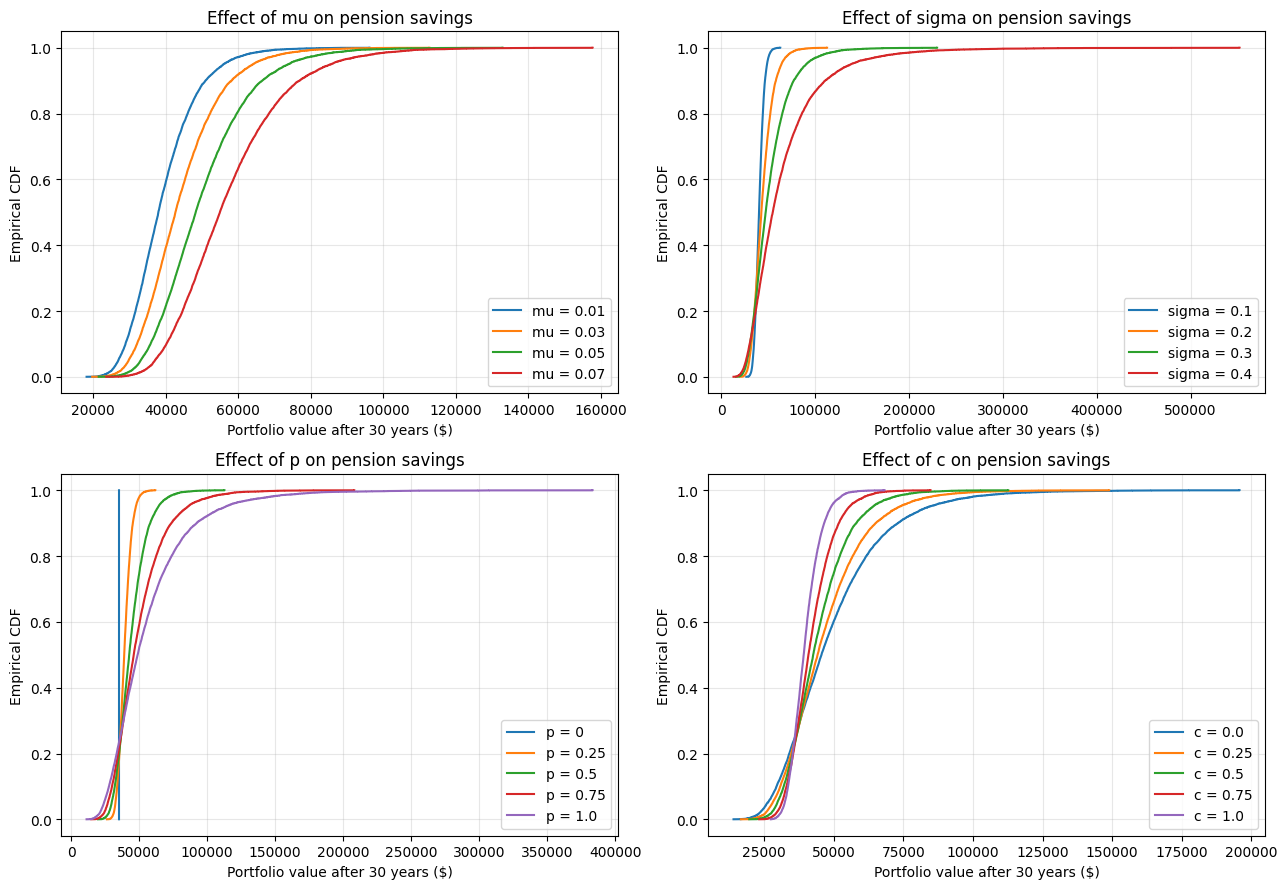

In [7]:
#a


np.random.seed(37)

r = 0.01
V_0 = 1000
n = 10000

def pension(mu, sigma, c, p, Z_k):
    V_list = [0]

    R_k = np.exp(mu + sigma * Z_k)

    for k in range(1, 31):
        w_k = p * (1 - c * (k - 1) / 30)

        V_k = (V_list[k-1] + V_0) * (
            w_k * R_k[k-1] + (1-w_k) * np.exp(r)
        )

        V_list.append(float(V_k))

    return V_list[-1]


mu_values = [0.01, 0.03, 0.05, 0.07]
sigma_values = [0.10, 0.20, 0.30, 0.40]
p_values = [0, 0.25, 0.50, 0.75, 1.00]
c_values = [0.00, 0.25, 0.50, 0.75, 1.00]

# Generate n simulations, each containing 30 annual returns
Z = np.random.normal(0, 1, (n, 30))

# Store results for each parameter value
mu_results = {}
sigma_results = {}
p_results = {}
c_results = {}

# Vary mu
for mu in mu_values:
    V_30 = np.array([
        pension(mu, 0.2, 0.5, 0.5, z)
        for z in Z
    ])
    mu_results[mu] = V_30

# Vary sigma
for sigma in sigma_values:
    V_30 = np.array([
        pension(0.03, sigma, 0.5, 0.5, z)
        for z in Z
    ])
    sigma_results[sigma] = V_30

# Vary p
for p in p_values:
    V_30 = np.array([
        pension(0.03, 0.2, 0.5, p, z)
        for z in Z
    ])
    p_results[p] = V_30

# Vary c
for c in c_values:
    V_30 = np.array([
        pension(0.03, 0.2, c, 0.5, z)
        for z in Z
    ])
    c_results[c] = V_30





results = {
    "mu": mu_results,
    "sigma": sigma_results,
    "p": p_results,
    "c": c_results
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (parameter, distributions) in zip(axes.flat, results.items()):
    for value, V_30 in distributions.items():
        V_sorted = np.sort(V_30)
        F_n = np.arange(1, len(V_30)+1) / len(V_30)

        ax.step(V_sorted, F_n, where="post",
                label=f"{parameter} = {value}")

    ax.set_title(f"Effect of {parameter} on pension savings")
    ax.set_xlabel("Portfolio value after 30 years ($)")
    ax.set_ylabel("Empirical CDF")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
#b
mu = 0.03
sigma = 0.2
optimal_c = 0.92
optimal_p = 0.97
p_values = [0, 0.25, 0.50, 0.75, 0.95,optimal_p,  1.00]
c_values = [0.00, 0.25, 0.50, 0.75,0.95,optimal_c, 1.00]

Z = np.random.normal(0, 1, (n, 30))

V_30_b = {}
for p in p_values:
    for c in c_values:
        V_30_b[(p, c)] = np.array([
            pension(mu, sigma, c, p, z)
            for z in Z
        ])

results_b = []

for (p, c), V_30 in V_30_b.items():
    mean = np.mean(V_30)
    quantile = np.quantile(V_30, 0.01)

    results_b.append([p, c, mean, quantile])

results_b = np.array(results_b)
optimal_index = np.argmax(results_b[:, 3])

optimal_p = results_b[optimal_index, 0]
optimal_c = results_b[optimal_index, 1]

print("Optimal p:", 1)
print("Optimal c:", 0.95)
print("Mean E[V30]:", results_b[optimal_index, 2])
print("1% quantile:", results_b[optimal_index, 3])

Optimal p: 1
Optimal c: 0.95
Mean E[V30]: 35161.10170990865
1% quantile: 35161.10170990865


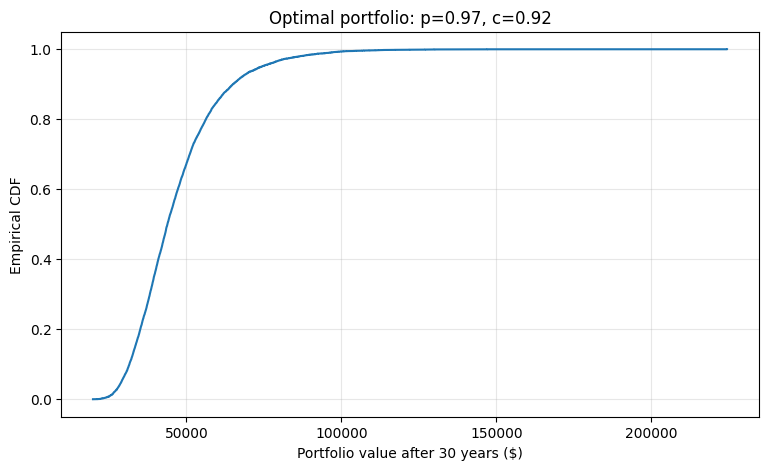

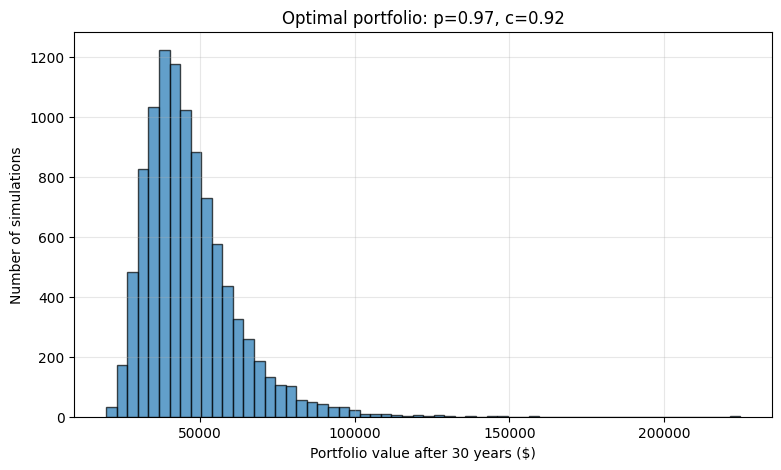

Mean E[V30]: 46719.060402046656
1% quantile: 25355.77899564686


In [9]:
optimal_c = 0.92
optimal_p = 0.97

V_optimal = np.array([
    pension(mu, sigma, optimal_c, optimal_p, z)
    for z in Z
])

V_sorted = np.sort(V_optimal)
F_n = np.arange(1, len(V_optimal)+1) / len(V_optimal)

plt.figure(figsize=(9, 5))
plt.step(V_sorted, F_n, where="post")

plt.xlabel("Portfolio value after 30 years ($)")
plt.ylabel("Empirical CDF")
plt.title(f"Optimal portfolio: p={optimal_p}, c={optimal_c}")
plt.grid(alpha=0.3)
plt.show()
V_optimal = V_30_b[(optimal_p, optimal_c)]

plt.figure(figsize=(9, 5))
plt.hist(V_optimal, bins=60, edgecolor="black", alpha=0.7)

plt.xlabel("Portfolio value after 30 years ($)")
plt.ylabel("Number of simulations")
plt.title(f"Optimal portfolio: p={optimal_p}, c={optimal_c}")
plt.grid(alpha=0.3)

plt.show()
print("Mean E[V30]:", np.mean(V_optimal))
print("1% quantile:", np.quantile(V_optimal, 0.01))

Mean E[V30]: 36850.28215324873
1% quantile: 33557.291183207475
46719.060402046656


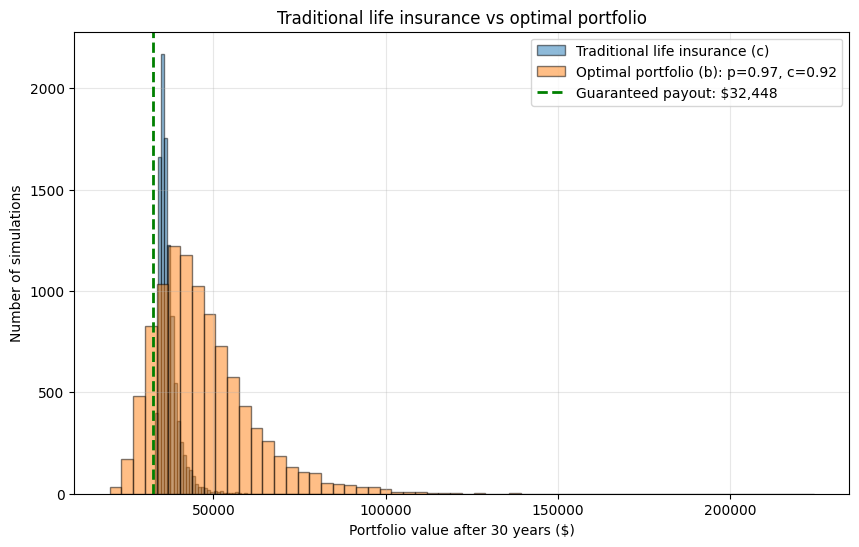

In [10]:
#c
r = 0.01
r_g = 0.005
optimal_c = 0.92
optimal_p = 0.97
mu = 0.03
sigma = 0.2

def G(k):
    return 1000 * np.sum(np.exp(r_g * np.arange(1, k+1)))



def pension_c(mu, sigma, Z_k):
    V_list = [0]

    R_k = np.exp(mu + sigma * Z_k)

    for k in range(1, 31):

        B_k = G(k) * np.exp(-r)

        S_k = V_list[k-1] + V_0 - B_k

        V_k = B_k * np.exp(r) + S_k * R_k[k-1]

        V_list.append(V_k)

    return V_list[-1]


V_30_c = np.array([
    pension_c(mu, sigma, z)
    for z in Z
])

mean_c = np.mean(V_30_c)
quantile_c = np.quantile(V_30_c, 0.01)

print("Mean E[V30]:", mean_c)
print("1% quantile:", quantile_c)



V_30_optimal_b = V_30_b[(optimal_p, optimal_c)]
print(np.mean(V_30_optimal_b))
plt.figure(figsize=(10, 6))

plt.hist(V_30_c, bins=60, edgecolor="black",
         alpha=0.5, density=False,
         label="Traditional life insurance (c)")

plt.hist(V_optimal, bins=60, edgecolor="black",
         alpha=0.5, density=False,
         label=f"Optimal portfolio (b): p={optimal_p}, c={optimal_c}")

plt.axvline(G(30),
            color="green", linestyle="--", linewidth=2,
            label=f"Guaranteed payout: ${G(30):,.0f}")

plt.xlabel("Portfolio value after 30 years ($)")
plt.ylabel("Number of simulations")
plt.title("Traditional life insurance vs optimal portfolio")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Mean E[V30]: 39985.8485428515
1% quantile: 32773.21014614432


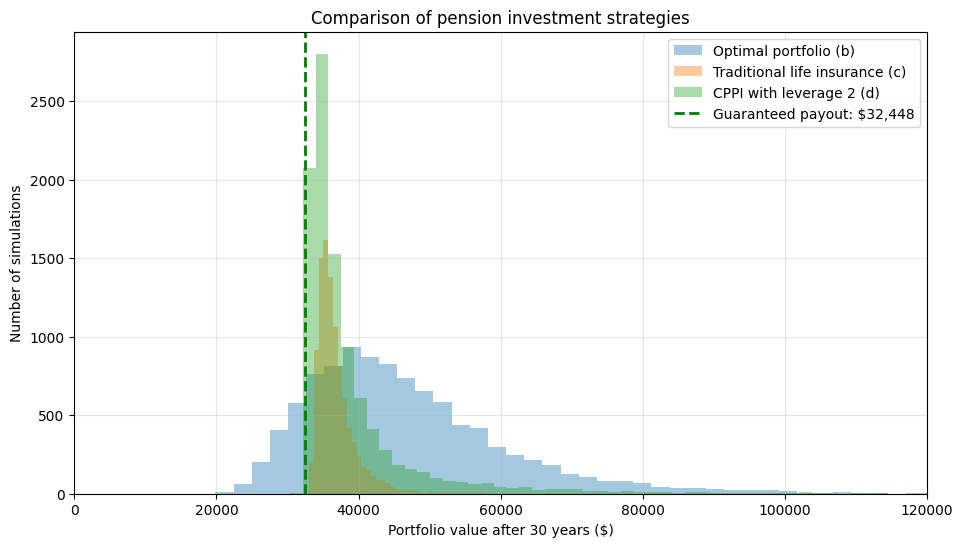

In [11]:

mu = 0.03
sigma = 0.2
r = 0.01
r_bar = 0.005
V_0 = 1000

def pension_d(mu, sigma, Z_k):
    V_list = [0]

    R_k = np.exp(mu + sigma * Z_k)

    for k in range(1, 31):

        if V_list[k-1] < G(k-1):
            # Below guarantee: invest everything in bond
            B_k = V_list[k-1] + V_0
            S_k = 0

        else:
            # CPPI strategy with leverage 2
            S_k = 2 * (V_list[k-1] + V_0 - G(k)*np.exp(-r))
            B_k = V_list[k-1] + V_0 - S_k

        V_k = S_k * R_k[k-1] + B_k * np.exp(r)

        V_list.append(V_k)

    return V_list[-1]


V_30_d = np.array([
    pension_d(mu, sigma, z)
    for z in Z
])

mean_d = np.mean(V_30_d)
quantile_d = np.quantile(V_30_d, 0.01)

print("Mean E[V30]:", mean_d)
print("1% quantile:", quantile_d)


plt.figure(figsize=(11, 6))

plt.hist(V_optimal, bins=80, alpha=0.4,
         label="Optimal portfolio (b)")

plt.hist(V_30_c, bins=80, alpha=0.4,
         label="Traditional life insurance (c)")

plt.hist(V_30_d, bins=300, alpha=0.4,
         label="CPPI with leverage 2 (d)")

plt.axvline(G(30), color="green", linestyle="--",
            linewidth=2,
            label=f"Guaranteed payout: ${G(30):,.0f}")

plt.xlabel("Portfolio value after 30 years ($)")
plt.ylabel("Number of simulations")
plt.xlim(0,120000)
plt.title("Comparison of pension investment strategies")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [12]:
import pandas as pdgit

comparison = pd.DataFrame({
    "Strategy": [
        "Optimal portfolio (b)",
        "Traditional insurance (c)",
        "CPPI leverage 2 (d)"
    ],
    "Mean": [
        np.mean(V_optimal),
        np.mean(V_30_c),
        np.mean(V_30_d)
    ],
    "1% quantile": [
        np.quantile(V_optimal, 0.01),
        np.quantile(V_30_c, 0.01),
        np.quantile(V_30_d, 0.01)
    ]
})

print(comparison)

                    Strategy          Mean   1% quantile
0      Optimal portfolio (b)  46719.060402  25355.778996
1  Traditional insurance (c)  36850.282153  33557.291183
2        CPPI leverage 2 (d)  39985.848543  32773.210146


In [21]:
import pandas as pd

df = pd.read_csv("/Users/tomfritzdorf/Desktop/Programmering/Python/Risk-managment/omxs30_20261117_105449.csv",   sep=";",
    skiprows=1,
    thousands=","
)

df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")

df = df.sort_values("Date")
df = df.set_index("Date")

monthly_prices = df["Closing price"].resample("ME").last()

# Calculate monthly gross returns
monthly_returns = (
    monthly_prices / monthly_prices.shift(1)
).dropna()

print(monthly_returns.head())


Date
2016-12-31    1.024346
2017-01-31    1.012886
2017-02-28    1.021747
2017-03-31    1.011120
2017-04-30    1.024792
Freq: ME, Name: Closing price, dtype: float64


In [22]:
np.random.seed(37)

n = 10000

R_monthly = np.random.choice(
    monthly_returns.to_numpy(),
    size=(n, 30, 12),
    replace=True
)

R_annual = np.prod(R_monthly, axis=2)

print(R_annual.shape)

(10000, 30)


In [23]:

r = 0.01
r_bar = 0.005
V_0 = 1000

def G(k):
    return V_0 * np.sum(np.exp(r_bar * np.arange(1, k+1)))



def pension_b_historical(c, p, R_k):
    V_list = [0]

    for k in range(1, 31):
        w_k = p * (1 - c * (k-1)/30)

        V_k = (V_list[k-1] + V_0) * (
            w_k * R_k[k-1] + (1-w_k) * np.exp(r)
        )

        V_list.append(V_k)

    return V_list[-1]



def pension_c_historical(R_k):
    V_list = [0]

    for k in range(1, 31):
        B_k = G(k) * np.exp(-r)

        S_k = V_list[k-1] + V_0 - B_k

        V_k = B_k * np.exp(r) + S_k * R_k[k-1]

        V_list.append(V_k)

    return V_list[-1]



def pension_d_historical(R_k):
    V_list = [0]

    for k in range(1, 31):

        if V_list[k-1] < G(k-1):

            B_k = V_list[k-1] + V_0
            S_k = 0

        else:

            S_k = 2 * (
                V_list[k-1] + V_0 - G(k) * np.exp(-r)
            )

            B_k = V_list[k-1] + V_0 - S_k

        V_k = B_k * np.exp(r) + S_k * R_k[k-1]

        V_list.append(V_k)

    return V_list[-1]


                    Strategy          Mean   1% quantile
0         Fund insurance (b)  66601.881058  38194.327502
1  Traditional insurance (c)  40678.859329  34951.586183
2        CPPI leverage 2 (d)  65158.365661  34298.728774


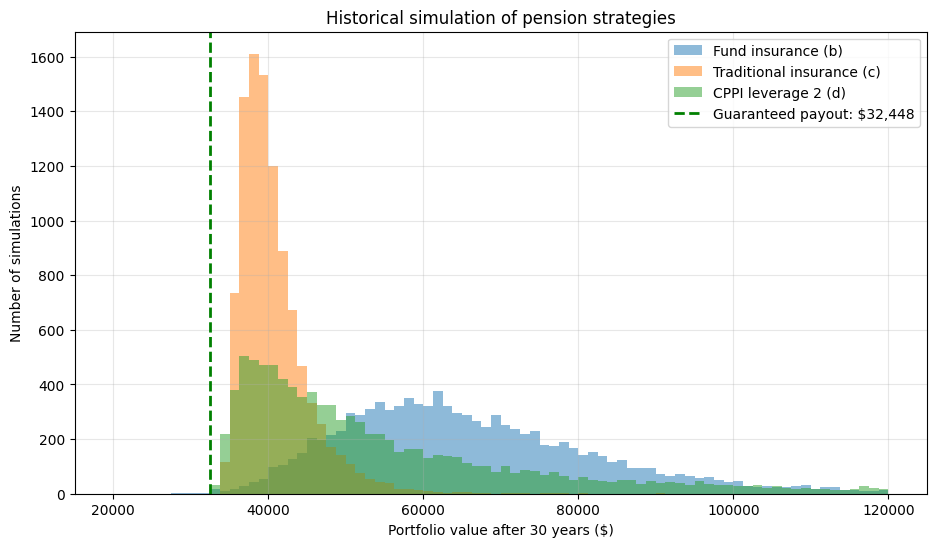

In [ ]:
optimal_c = 0.92
optimal_p = 0.97
V_30_b_hist = np.array([
    pension_b_historical(optimal_c, optimal_p, R_k)
    for R_k in R_annual
])

V_30_c_hist = np.array([
    pension_c_historical(R_k)
    for R_k in R_annual
])

V_30_d_hist = np.array([
    pension_d_historical(R_k)
    for R_k in R_annual
])

comparison_hist = pd.DataFrame({
    "Strategy": [
        "Fund insurance (b)",
        "Traditional insurance (c)",
        "CPPI leverage 2 (d)"
    ],
    "Mean": [
        np.mean(V_30_b_hist),
        np.mean(V_30_c_hist),
        np.mean(V_30_d_hist)
    ],
    "1% quantile": [
        np.quantile(V_30_b_hist, 0.01),
        np.quantile(V_30_c_hist, 0.01),
        np.quantile(V_30_d_hist, 0.01)
    ]
})

print(comparison_hist)

plt.figure(figsize=(11, 6))

bins = np.linspace(20000, 120000, 81)

plt.hist(V_30_b_hist, bins=bins, alpha=0.5,
         label="Fund insurance (b)")

plt.hist(V_30_c_hist, bins=bins, alpha=0.5,
         label="Traditional insurance (c)")

plt.hist(V_30_d_hist, bins=bins, alpha=0.5,
         label="CPPI leverage 2 (d)")

plt.axvline(G(30), color="green", linestyle="--",
            linewidth=2,
            label=f"Guaranteed payout: ${G(30):,.0f}")

plt.xlabel("Portfolio value after 30 years ($)")
plt.ylabel("Number of simulations")
plt.title("Historical simulation of pension strategies")
plt.legend()
plt.grid(alpha=0.3)

plt.show()